The setup is a computer connected via USB to an <u>Adafruit FT232H</u> which is connected to <u>Adafruit PCA9548 8-Channel I2C Multiplexer</u>. This is houses the connection to all eight <u>Adafruit MMC5603 magnetometer</u>. The magnetometer are labeled 0 to 7.

The sole purpose of the Adafruit FT232H is to convert the signals recieved from all eight magnetometers into a format usable for USB connection to laptops. Each magnetometer has the address <u>0x30</u>. The hub (Adafruit PCA9548 8-Channel I2C Multiplexer) to which all eight magnetometers are connected to has address <u>0x70</u>. When coding, do not mix them up.

This is a Jupyter Notebook rather than a Python script file. To sucessfully run, run the following cells in order.

If you get an error that hard to resolve, you may need to do the following:
    1. Install the Zadig driver tool (https://zadig.akeo.ie)
    2. Plug in the USB to computer
    3. Open downloaded driver tool
    4. Click through until you see an option along the lines of "Replace its driver"
    5. I'm not sure what this is exactly used for, but I did it to debug my errors. Not sure if it was nessesary, but if there are any bugs, this may be the step you need to take.
    

DO NOT, WHEN INSTALLING OR IMPORTING, INTERRUPT OR RESTART THE KERNAL. YOU WILL END UP GETTING FRAGMENTED FILES WHICH ARE A PAIN TO REMOVE AND TRACK

DO NOT RUN THE CELLS OUT OF ORDER (ESPECIALLY THE INSTALLING LIBRARIES ONES) UNTILL YOU GET TO THE DATA COLLECTION CELLS

In [1]:
# This is all the nessesary libraries and imports. 
# after installment, you will NOT need to reinstall. You can just use import which is on the next cell

import sys

!{sys.executable} -m pip install --upgrade pip setuptools wheel
!{sys.executable} -m pip install --upgrade pyftdi
!{sys.executable} -m pip install --upgrade adafruit-blinka
!{sys.executable} -m pip install --upgrade adafruit-circuitpython-tca9548a
!{sys.executable} -m pip install --upgrade adafruit-circuitpython-mmc56x3
!{sys.executable} -m pip install --upgrade libusb-package
!{sys.executable} -m pip install --upgrade matplotlib
!{sys.executable} -m pip install --upgrade setuptools

In [2]:
import os
import libusb_package
import usb.backend.libusb1

os.environ["BLINKA_FT232H"] = "1"

_original_get_backend = usb.backend.libusb1.get_backend
def _patched_get_backend(find_library=None, *args, **kwargs):
    return _original_get_backend(find_library=libusb_package.find_library, *args, **kwargs)
usb.backend.libusb1.get_backend = _patched_get_backend


In [3]:
# importing stuff, assuming you installed already using the last cell, run this just in case
# make sure your USB is plugged in at this point

import matplotlib.pyplot as plt

from pyftdi.usbtools import UsbTools
import board
import busio
import adafruit_tca9548a
import adafruit_mmc56x3

In [4]:
i2c = board.I2C()
mux = adafruit_tca9548a.TCA9548A(i2c)
sensor_i2c = mux[0]  # channel the MMC5603 is plugged into

In [5]:
while not sensor_i2c.try_lock():
    pass
try:
    print([hex(a) for a in sensor_i2c.scan()])
finally:
    sensor_i2c.unlock()

['0x70']


In [6]:
# very important, this line initializes the sensors and allows them to be read from. 
# If you want to only read from one sensor, you need to change the range. 
# However, it's probably better if you just unplug it and only read the plots you want the sensor from.
sensors = {}
for ch in range(8):
    while not mux[ch].try_lock():
        pass
    try:
        addrs = mux[ch].scan()
    finally:
        mux[ch].unlock()
    if 0x30 in addrs:
        sensors[ch] = adafruit_mmc56x3.MMC5603(mux[ch])

print(sensors)

{2: <adafruit_mmc56x3.MMC5603 object at 0x00000207535BCAD0>}


In [20]:
# This only reads ONE sensor. You can change the sensor you read from by changing the index in sensors fro sensor[0] to sensor[1] or sensor[2] etc.
# This collects the magnetic field data from the sensor at that moment you run the code. It is not continuous and you will need to run the code again to get new data.
mag_x, mag_y, mag_z = sensors[2].magnetic
print(f"X: {mag_x:.2f} uT  Y: {mag_y:.2f} uT  Z: {mag_z:.2f} uT")

X: -15.31 uT  Y: 33.42 uT  Z: 138.46 uT


In [9]:
# This is the code to read all the sensors and print their magnetic field data. It will print the data for all 8 sensors ONCE.
for ch, s in sensors.items():
    y, x, z = s.magnetic
    print(f"Sensor (channel {ch}): X={x:.2f}  Y={y:.2f}  Z={z:.2f} uT")

Sensor (channel 2): X=-13.11  Y=-1262.66  Z=41.34 uT


In [ ]:
import time
import math

total_time = 2  # seconds

timestamps = []
data = {ch: {"x": [], "y": [], "z": []} for ch in sensors}  # only real channels

start = time.monotonic()
while time.monotonic() - start < total_time:
    t = time.monotonic() - start
    timestamps.append(t)
    for ch, s in sensors.items():
        try:
            y, x, z = s.magnetic
        except Exception:
            x, y, z = float('nan'), float('nan'), float('nan')
        data[ch]["x"].append(x)
        data[ch]["y"].append(y)
        data[ch]["z"].append(z)

print(f"Collected {len(timestamps)} samples over {timestamps[-1]:.1f}s")

def safe_mean(values):
    valid = [v for v in values if not math.isnan(v)]
    return sum(valid) / len(valid) if valid else float('nan')

# Compute averages per sensor/axis
averages = {}
for ch in sensors:
    averages[ch] = {
        "x": safe_mean(data[ch]["x"]),
        "y": safe_mean(data[ch]["y"]),
        "z": safe_mean(data[ch]["z"]),
        "n_valid": sum(1 for v in data[ch]["x"] if not math.isnan(v)),
    }

print("\nAverage readings over interval:")
print(f"{'Sensor':<8}{'Avg X':>10}{'Avg Y':>10}{'Avg Z':>10}{'Valid/Total':>14}")
for ch in sensors:
    a = averages[ch]
    print(f"{ch:<8}{a['x']:>10.2f}{a['y']:>10.2f}{a['z']:>10.2f}{a['n_valid']:>10}/{len(timestamps)}")


Collected 7 samples over 1.9s

Average readings over interval:
Sensor       Avg X     Avg Y     Avg Z   Valid/Total
2           -35.44    -24.79     28.62         7/7
7            19.56    -29.66    -49.90         7/7


In [ ]:
#axes fixed

import time

total_time = 2  # seconds
timestamps = []
data = {ch: {"x": [], "y": [], "z": []} for ch in sensors}

# Define your custom geometry transformations for each sensor ID
# Use 'raw_x', 'raw_y', 'raw_z' to map to the true system axes
axis_configs = {
    0: lambda rx, ry, rz: (rz, -ry, rx),    # Sensor 2
    1: lambda rx, ry, rz: (-rz, -ry, -rx),   # Sensor 7
}

start = time.monotonic()
while time.monotonic() - start < total_time:
    t = time.monotonic() - start
    timestamps.append(t)
    
    for ch, s in sensors.items():
        try:
            # 1. Read hardware raw values
            rx, ry, rz = s.magnetic
            
            # 2. Apply the specific mapping for this sensor channel
            if ch in axis_configs:
                x_val, y_val, z_val = axis_configs[ch](rx, ry, rz)
            else:
                x_val, y_val, z_val = rx, ry, rz  # Fallback default
                
        except Exception:
            x_val, y_val, z_val = float('nan'), float('nan'), float('nan')
        
        data[ch]["x"].append(x_val)
        data[ch]["y"].append(y_val)
        data[ch]["z"].append(z_val)

print(f"Collected {len(timestamps)} samples over {timestamps[-1]:.1f}s")

# Optional table view
header = "Time(s)  " + "  ".join([f"S{ch}_X    S{ch}_Y    S{ch}_Z" for ch in sensors])
print(header)
for row_i, t in enumerate(timestamps):
    row = f"{t:6.2f}   "
    for ch in sensors:
        x = data[ch]["x"][row_i]
        y = data[ch]["y"][row_i]
        z = data[ch]["z"][row_i]
        row += f"{x:7.2f} {y:7.2f} {z:7.2f}  "
    print(row)



Collected 7 samples over 1.9s
Time(s)  S2_X    S2_Y    S2_Z  S7_X    S7_Y    S7_Z
  0.00     37.45    6.83 2184.71    33.69  -72.41 -2170.28  
  0.33     37.77    7.40 2184.41    33.52  -71.96 -2170.78  
  0.64     37.58    7.53 2184.83    33.74  -72.09 -2170.43  
  0.94     37.61    6.93 2185.09    33.83  -72.16 -2170.93  
  1.25     37.48    6.57 2184.36    33.69  -72.23 -2170.26  
  1.56     37.46    6.78 2184.53    33.69  -71.82 -2169.56  
  1.87     37.46    6.73 2184.74    33.72  -72.42 -2170.47  


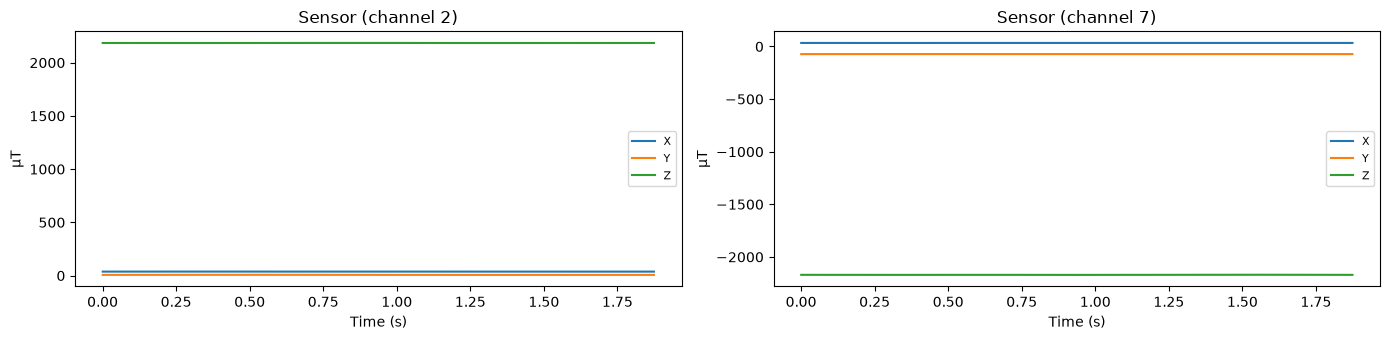

In [ ]:


n = len(sensors)
ncols = 2
nrows = (n + 1) // ncols  # ceil division, so odd counts still fit

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows), sharex=True)
axes = axes.flatten() if n > 1 else [axes]

for idx, ch in enumerate(sensors):
    axes[idx].plot(timestamps, data[ch]["x"], label="X")
    axes[idx].plot(timestamps, data[ch]["y"], label="Y")
    axes[idx].plot(timestamps, data[ch]["z"], label="Z")
    axes[idx].set_title(f"Sensor (channel {ch})")
    axes[idx].set_ylabel("µT")
    axes[idx].legend(fontsize=8)

# hide any unused subplot axes (if n is odd, one slot is empty)
for j in range(n, len(axes)):
    axes[j].set_visible(False)

# label x-axis only on bottom-row plots
for idx in range(max(0, n - ncols), n):
    axes[idx].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()